In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 3/6/2022
# version ='1.0'

# Demo: Solving Analytic Center of a Linear Matrix Equality

Consider the following problem in solving the analytic center under a linear matrix equality.

\begin{equation}
\begin{array}{rl}
\text{minimize} & f(X)=-\log\text{det} X\\
\text{subject to} & \text{tr}(A_iX) = b_i, i=1,...,p \\
\end{array}
\end{equation}
where $X\in \mathbf{dom}f=S^n_{++}$, $A_i\in S^n$, $b_i\in R$. 

Two efficient methods were discussed in [book-convex-2004], section 10.4. The first method is to solve the dual problem,
\begin{equation}
\begin{array}{rl}
\text{maximize} & g(\nu)=-b^T\nu + \log\text{det}\left(\displaystyle{\sum_{i=1}^p \nu_iA_i} \right) + n
\end{array}
\end{equation}
where the domain is $\mathbf{dom}g=\{\nu|\displaystyle{\sum_{i=1}^p \nu_iA_i \succ 0} \}$. The gradient and the hessian of $g$ are the following (which are proved in the appendix)
\begin{equation}
\label{equ:NL38-gnu}
\begin{array}{rclcl}
\nabla g(\nu)_i & = & \text{tr}(A^{-1}A_i)-b_i & , & i=1,....,p \\
\nabla^2 g(\nu)_{i,j} & = & -\text{tr}(A^{-1}A_iA^{-1}A_j) & , & i,j=1,...,p \\
\end{array}
\end{equation}
where $A=\left(\displaystyle{\sum_{i=1}^p \nu_iA_i}\right)$.

The Newton's method in solving the dual problem is

### Newton method in solving the dual problem

given a starting point $\nu\in\mathbf{dom} g$, tolerance $\epsilon>0$

repeat:
\begin{enumerate}
\item compute the Newton step and the decrement
$$
\begin{array}{rcl}
	\Delta\nu_{nt} \leftarrow -[\nabla^2 g(\nu)]^{-1} [\nabla g(\nu)] & & \lambda^2\leftarrow [\nabla g(\nu)]^T[\nabla^2 g(\nu)]^{-1}[\nabla g(\nu)] \\
\end{array}
$$
\item if $\lambda^2/2\leq \epsilon$, then break
\item choose the step size $t$ by backtracking line search while ensuring $\nu+t\Delta\nu_{nt}\in \mathbf{dom}g$
\item update $\nu \leftarrow \nu+t\Delta\nu_{nt}$
\end{enumerate}



Another method is to solve the primal problem by deriving the Newton step $\Delta X_n$ from the KKT system at a feasible $X$. The KKT system for the primal problem is first approximated by the first-order of $X^{-1}$, that is

\begin{equation}
\begin{array}{rcl}
-(X+\Delta X_{nt})^{-1}+\displaystyle{\sum_{i=1}^mw_iA_i}=0 & & tr(A_i(X+\Delta X_{nt}))=b_i,i=1,...,p \\
(X+\Delta X_{nt})^{-1}\approx X^{-1}-X^{-1}\Delta X_{nt}X^{-1} & & tr(A_iX)=b_i,i=1,...,p \\
\end{array}
\end{equation}


By using block elimination, the solutions of $w,\Delta X_{nt}$ and the decrement can be solved as,

\begin{equation}
\begin{array}{rclcl}
\displaystyle{\sum_{j=1}^p} w_j tr(A_iXA_jX) & = & tr(A_iX)& & i=1,...,p \\
\Delta X_{nt} & = & X - \displaystyle{\sum_{j=1}^p}w_jXA_jX \\
\lambda^2 & = & tr(\Delta X_{nt}X^{-1}\Delta X_{nt}X^{-1}) \\
\end{array}
\end{equation}

The Newton's method in solving the primal problem is listed in Algorithm 

### Newton method in solving the primal problem

given a starting feasible point $X$, tolerance $\epsilon>0$

repeat
\begin{enumerate}
\item compute the Newton step $\Delta X_{mt}$ and the decrement $\lambda^2$ according to equation [\ref{equ:NL38-Alg2}
\item if $\lambda^2/2\leq \epsilon$, then break
\item choose the step size $t$ by backtracking line search while ensuring $X+t\Delta X_{nt}\in \mathbf{dom}f$
\item update $X \leftarrow X+t\Delta X_{nt}$
\end{enumerate}



A challenge is to find a starting feasible point $X_0$ to satisfy the equality constraints $\text{tr}(A_iX_0)=b_i,i=1,...,p$. It requires to search for a solution $X_0$ satisfying the $p$ linear equations with $n(n+1)/2$ variables in $X_0$  while keeping $X_0$ be positive definite. A heuristic method is to first randomly generate $X_0 \succ 0$, and then adjust $X_0$'s diagonal elements to satisfy $tr(A_iX_0)=b_i,i=1,...,p$; after such adjustment to $X_0$, the positiveness will be checked again, if $X_0$ is not positive adjustment again, then regenerate $X_0$ randomly again and repeat the procedure again.

In this demo, some experiments with $n=6$ and $p=6$ are simulated. The parameters $A_i, b_i, i=1,...,p$ are generated to satisfy the following KKT condition in the following:

$$
\begin{array}{rcl}
-X^{*-1}+\displaystyle{\sum_{i=1}^p \nu_i^*A_i} = 0 & & \text{tr}(A_iX^*)=b_i,i=1,...,p \\
\end{array}
$$ 

### Steps to generate feasible parameters $A_i, b_i, i=1,...,p$
repeat
\begin{enumerate}
\item generate each $A_i\leftarrow U_i^T D_i U_i$, $i=1,...,p$, where $U_i$ is a random orthogonal matrix generated by \textit{scipy.stats.ortho\_group.rvs} function, and $D_i$ is a diagonal matrix with elements in $\mathbf{U}(0,1)^n$
\item generate $\nu \in \mathbf{U}(-1,1)^p$ randomly and calculate $X^{-1} \leftarrow \displaystyle{\sum_{i=1}^p} \nu_iA_i$
\item if $X^{-1}$ is a positive definite matrix, return $X$ and break
\end{enumerate}


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
from scipy.stats import ortho_group

In [3]:
class Analytic_Center_LMI:

    def get_feasible_pA_b(self, n, p):
        """
        Generate feasbible model parameters, $A_i, b_i, i=1,2,...,p$
        Refer to the flexible lecture notes
        :param n:
        :param p:
        :return:
        """
        pA = np.zeros((p, n, n))  # pA：point to an array of A
        n_drial = 0
        while True:
            for i in range(p):
                R = ortho_group.rvs(n)
                D = np.random.uniform(0, 1, (n,))
                pA[i] = R @ np.diag(D) @ R.T
                if not np.linalg.matrix_rank(pA[i]) == n:
                    raise RuntimeError('Ai should be symmetric')

            nu_asterisk = np.random.uniform(-1, 1, (p, 1))
            X_asterisk_inv = np.zeros((n, n))
            for i in range(p):
                X_asterisk_inv = X_asterisk_inv + nu_asterisk[i, 0] * pA[i]
            if np.all(np.linalg.eigvals(X_asterisk_inv) > 0):
                print('Info: found feasible Xp')
                X_asterisk = np.linalg.inv(X_asterisk_inv)
                b = np.zeros((p, 1))
                for i in range(p):
                    b[i, 0] = np.trace(pA[i] @ X_asterisk)

                A_asterisk = np.zeros((n, n))
                for i in range(p):
                    A_asterisk = A_asterisk + nu_asterisk[i, 0] * pA[i]
                if not np.allclose(-np.linalg.inv(X_asterisk) + A_asterisk, 0):
                    raise RuntimeError('The KKT conditions on dual failed')
                if not np.all(np.linalg.eigvals(A_asterisk) > 0):
                    raise RuntimeError('A should be positive definite')
                for i in range(p):
                    if not np.allclose(np.trace(pA[i] @ X_asterisk), b[i, 0]):
                        raise RuntimeError('The KKT conditions on primal failed')

                return pA, b, X_asterisk, nu_asterisk
            else:
                print('Info: num of drial in construct A, b ={}'.format(n_drial))
                n_drial = n_drial + 1

In [4]:
class Analytic_Center_LMI_Alg1(Analytic_Center_LMI):

    def get_feasible_nu0(self, n, p, pA):
        """
        search for a feasible $\nu_0$ to satisfy

        $$
        \sum_{i=1}^p \nu_iA_i \succ 0
        $$

        :param n:
        :param p:
        :param pA:
        :return:
        """
        n_dial = 0
        while True:
            nu0 = np.random.uniform(-1, 1, (p, 1))
            A = np.zeros((n, n))
            for i in range(p):
                A = A + nu0[i, 0] * pA[i]

            if np.all(np.linalg.eigvals(A) > 0):
                print('Info: found feasible nu0')
                # print('eigen values of A ={}'.format(np.linalg.eigvals(A)))
                return nu0
            else:
                print('Info: num of dial in searching for a start point nu0 = {}'.format(n_dial))
                n_dial = n_dial + 1

    def my_dual_f(self, nu, pA, b, A, pA_A):
        """
        The dual function to minimize is
        $$
        b^T\nu - \log\text{det}\left(\displaystyle{\sum_{i=1}^p \nu_iA_i} \right) + n
        $$
        :param nu:
        :param pA:
        :param b:
        :param A:
        :param pA_A:
        :return:
        """
        n = pA.shape[1]
        return (b.T @ nu).item() - np.log(np.linalg.det(A)) - n

    def my_feasible_dual_f(self, nu, pA, b, A, pA_A):
        """
        The domain is $\textbf{dom}g=\{\nu|A=\displaystyle{\sum_{i=1}^p \nu_iA_i \succ 0} \}$
        :param nu:
        :param pA:
        :param b:
        :param A:
        :param pA_A:
        :return:
        """
        return np.all(np.linalg.eigvals(A) > 0)

    def my_dual_gradient_f(self, nu, pA, b, A, pA_A):
        """
        $$
        \nabla g(\nu)_i = \text{tr}(A^{-1}A_i)-b_i , i=1,....,p
        $$
        :param nu:
        :param pA:
        :param b:
        :param A:
        :param pA_A: $A^{-1}A_i,i=1,2,...p$
        :return:
        """
        p = pA.shape[0]
        g = np.zeros((p, 1))
        for i in range(p):
            g[i] = b[i] - np.trace(pA_A[i])
        return g

    def my_dual_hessian_f(self, nu, pA, b, A, pA_A):
        """
        $$
        \nabla^2 g(\nu)_{i,j} = -\text{tr}(A^{-1}A_iA^{-1}A_j), i,j=1,...,p
        $$
        :param nu:
        :param pA:
        :param b:
        :param A:
        :param pA_A:
        :return:
        """
        p = pA.shape[0]
        n = pA.shape[1]
        h = np.zeros((n, n))
        for i in range(n):
            for j in range(n):
                h[i, j] = np.trace(pA_A[i] @ pA_A[j])
        return h

    def my_newton_step_decrement(self, nu, args):
        """
        compute the Newton step and the decrement
        $$
        \begin{array}{rcl}
	        \Delta\nu_{nt} \leftarrow -[\nabla^2 g(\nu)]^{-1} [\nabla g(\nu)] & & \lambda^2\leftarrow [\nabla g(\nu)]^T[\nabla^2 g(\nu)]^{-1}[\nabla g(\nu)] \\
        \end{array}
        $$
        :param nu:
        :param args:
        :return:
        """
        gradient = self.my_dual_gradient_f(nu, *args)
        hessian = self.my_dual_hessian_f(nu, *args)
        hessian_inv = np.linalg.inv(hessian)
        nu_nt = -1 * hessian_inv @ gradient
        decrement = -1 * gradient.T @ nu_nt
        return nu_nt, decrement.item()

    def backtracking_line_search(self, f, df, nu, delta_nu, alpha, beta, args):
        """
        the backtracking line search method implementation
        :param f:
        :param df:
        :param nu:
        :param delta_nu:
        :param alpha:
        :param beta:
        :param args:
        :return:
        """
        (pA, b, A, pA_A) = args

        p = pA.shape[0]
        n = pA.shape[1]
        t = 1
        next_nu = nu + t * delta_nu
        next_A = np.zeros((n, n))

        for i in range(p):
            next_A = next_A + next_nu[i, 0] * pA[i]
        while (not self.my_feasible_dual_f(next_nu, pA, b, next_A, None)) \
                or f(next_nu, pA, b, next_A, None) > f(nu, *args) + alpha * t * ((df(nu, *args).T @ delta_nu).item()):
            t = beta * t
            next_nu = nu + t * delta_nu
            next_A = np.zeros((n, n))
            for i in range(p):
                next_A = next_A + next_nu[i, 0] * pA[i]
        return t

    def plot_convergence_graph(self, n, p, seed, max_iteration=100):
        """
        plot the converge graph, $\lambda^2$ vs.  interation, and $g(\nu)-g(\nu^*)$ vs. iteration
        :return:
        """
        alpha = 0.01
        beta = 0.5
        epsilon = 1e-12

        np.random.seed(seed)
        pA, b, X_asterisk, nu_asterisk = self.get_feasible_pA_b(n, p)

        A_asterisk = np.zeros((n, n))
        for i in range(p):
            A_asterisk = A_asterisk + nu_asterisk[i, 0] * pA[i]
        g_nu_asterisk = self.my_dual_f(nu_asterisk, pA, b, A_asterisk, None)

        nu0 = self.get_feasible_nu0(n, p, pA)
        A0 = np.zeros((n, n))
        for i in range(p):
            A0 = A0 + nu0[i, 0] * pA[i]

        A0_inv = np.linalg.inv(A0)
        pA_A0 = np.zeros((p, n, n))  # pA_A = $A^{-1}A_i,i=1,2,...p$
        for i in range(p):
            pA_A0[i] = A0_inv @ pA[i]

        args = (pA, b, A0, pA_A0)
        nu_nt, decrement = self.my_newton_step_decrement(nu0, args)
        iteration = 0
        nu = nu0

        decrements = [decrement]
        g_nu = [self.my_dual_f(nu0, pA, b, A0, None)]

        while decrement / 2 > epsilon:
            print(r'Info: iteration = {}, decrement = {}'.format(iteration, decrement))
            t = self.backtracking_line_search(self.my_dual_f, self.my_dual_gradient_f, nu, nu_nt, alpha, beta, args)
            nu_next = nu + t * nu_nt
            nu = nu_next

            A = np.zeros((n, n))
            for i in range(p):
                A = A + nu[i, 0] * pA[i]
            A_inv = np.linalg.inv(A)
            pA_A = np.zeros((p, n, n))  # pA_A[i]=A^{-1}A_i, i=1,...,p
            for i in range(p):
                pA_A[i] = A_inv @ pA[i]

            args = (pA, b, A, pA_A)
            g_nu.append(self.my_dual_f(nu, *args))

            nu_nt, decrement = self.my_newton_step_decrement(nu, args)
            decrements.append(decrement)

            iteration = iteration + 1

            if iteration > max_iteration:
                print('WARNNIG: Algorithm is no converged, stop')
                break

        ax = plt.subplot(1, 2, 1)
        ax.semilogy(decrements, marker='+', label=r'$\lambda^2$')
        ax.grid()
        ax.legend()
        ax.set_xlabel('iteration')
        ax.set_title('decrement in Algorithm 1')
        ax.xaxis.set_major_formatter(FormatStrFormatter('%d'))

        ax = plt.subplot(1, 2, 2)
        ax.semilogy(np.abs(np.array(g_nu) - g_nu_asterisk), marker='x', label=r'$g(\nu)-g(\nu^*)$')
        ax.grid()
        ax.legend()
        ax.set_xlabel('iteration')
        ax.set_title(r'$g(\nu)-g(\nu^*)$ in Algorithm 1')
        ax.xaxis.set_major_formatter(FormatStrFormatter('%d'))

        plt.show()


Info: num of drial in construct A, b =0
Info: num of drial in construct A, b =1
Info: found feasible Xp
Info: num of dial in searching for a start point nu0 = 0
Info: num of dial in searching for a start point nu0 = 1
Info: found feasible nu0
Info: iteration = 0, decrement = 2.8801623610870917
Info: iteration = 1, decrement = 0.619704687589588
Info: iteration = 2, decrement = 0.11200956715227432
Info: iteration = 3, decrement = 0.004487516350173047
Info: iteration = 4, decrement = 8.689799676657469e-06
Info: iteration = 5, decrement = 4.022406022943372e-11


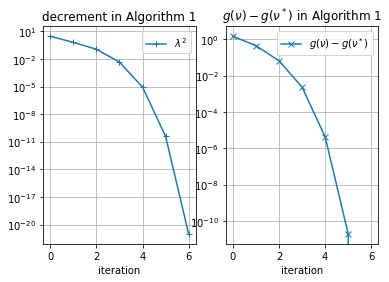

In [5]:
if __name__ == "__main__":
    alg1 = Analytic_Center_LMI_Alg1()
    alg1.plot_convergence_graph(n=6, p=6, seed=1)